> pip install tensorflow

In [2]:
#0. 필요한 모듈 사용
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

In [3]:
#1. fashion_mnist 데이터셋 읽어오기
dataset= tf.keras.datasets.fashion_mnist
# 훈련용 독립&종속, 테스트용 독립&종속 데이터 불러오기 (튜플로)
(x_train, y_train), (x_test, y_test)= dataset.load_data() 

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [6]:
# 분류명을 얻어오기. -- pytorch 처럼 classes 라는 속성은 없음.
# tf.keras가 아닌 tensorflow_datasets 라는 모듈에서 제공함.. 추가 설치 필요 [ pip install tensorflow-datasets ]
import tensorflow_datasets as tfds
fashion_mnist= tfds.builder('fashion_mnist')
class_names= fashion_mnist._info().features['label'].names
print(class_names)

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


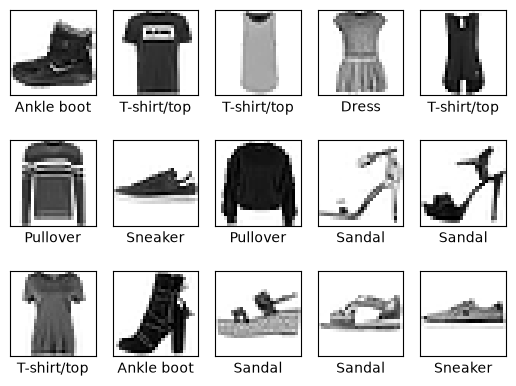

In [8]:
#2. 샘플 데이터 시각화
# 3행 5열로 이미지들을 그리기.
for i in range(15):
    plt.subplot(3,5, i+1)
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(x_train[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]])
plt.show()

In [9]:
#3. CNN 모델에서 합성곱 연상을 수행하기 적합하도록 픽셀값들을 전처리
x_train= x_train.reshape( x_train.shape[0], 28, 28, 1 ) / 255.0  # 3차원 --> 4차원 (데이터의 개수, 가로, 세로, 채널수) / 0~1 정규화
x_test= x_test.reshape( -1, 28, 28, 1 )

print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [10]:
#4. CNN 신경망 모델 설계하고 모델 생성
model= tf.keras.models.Sequential([
    #1) 특성 추출기
    tf.keras.layers.Conv2D(32, (3,3), padding='same', activation='relu', input_shape=(28,28,1)),  #특성맵 : 32개짜리.. 선, 면 등의 특성을 32개 추출
    tf.keras.layers.MaxPool2D((2,2), strides=2),
    tf.keras.layers.Conv2D(64, (3,3), padding='same'),
    tf.keras.layers.MaxPool2D((2,2), strides=2),

    #2) 분류기
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),  #은닉층
    tf.keras.layers.Dense(10, activation='softmax'), #출력층
])

c:\Users\mbc\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
#5. 손실함수, 최적화 준비
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [12]:
#6. 모델학습
model.fit(x_train, y_train, epochs=5)  #독립변수, 종속변수, 학습반복 횟수

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8589 - loss: 0.3909
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9066 - loss: 0.2520
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9248 - loss: 0.2046
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9400 - loss: 0.1671
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9524 - loss: 0.1334


In [ ]:
#7. 테스트 데이터셋으로 모델 성능평가
model.evaluate(x_test, y_test)  #보통 리스트로 loss, accuracy

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8906 - loss: 54.8771


[54.8770751953125, 0.8906000256538391]

In [14]:
#모델학습시 batch_size 인자 사용해보기
model.fit(
    x_train, y_train,
    batch_size= 64,   #지정하지 않으면 기본 32
    epochs= 10,
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9652 - loss: 0.0956
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9745 - loss: 0.0738
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9793 - loss: 0.0610
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9827 - loss: 0.0492
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9849 - loss: 0.0422
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9864 - loss: 0.0377
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9869 - loss: 0.0362
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9892 - loss: 0.0293
Epoch 9/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9897 - loss: 0.0281
Epoch 10/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9913 - loss: 0.0235
